# Historical full-sample exploratory analysis

This notebook describes the original 4,424 records, including 3,630 resolved cases. It predates the frozen split and indirectly explored the later reserved test set. The historical population section is exploratory resolved-case analysis; the current Q2 retains all three classes in part2_training.ipynb. Financial variables below have unverified measurement timing and are excluded from the enrolment model. Numeric outcome codes are labels, never a continuous outcome or the Q3 binary target.

Source: Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict Students' Dropout and Academic Success. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89 (CC BY 4.0).

### Imports

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, chi2_contingency
from statsmodels.stats.proportion import proportion_confint

### Load Dataset

In [2]:
data = pd.read_csv("data/data.csv", sep=";")
data.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

### Data Processing

In [4]:
data.isnull().sum()/len(data)*100

Marital status                                    0.0
Application mode                                  0.0
Application order                                 0.0
Course                                            0.0
Daytime/evening attendance\t                      0.0
Previous qualification                            0.0
Previous qualification (grade)                    0.0
Nacionality                                       0.0
Mother's qualification                            0.0
Father's qualification                            0.0
Mother's occupation                               0.0
Father's occupation                               0.0
Admission grade                                   0.0
Displaced                                         0.0
Educational special needs                         0.0
Debtor                                            0.0
Tuition fees up to date                           0.0
Gender                                            0.0
Scholarship holder          

No NaN values were detected; categorical unknown codes still require checking

In [5]:
print(data["Target"].unique())

<StringArray>
['Dropout', 'Graduate', 'Enrolled']
Length: 3, dtype: str


There are three unique target values: Dropout, Graduate and Enrolled

I'll encode them as:
- Dropout = 0
- Enrolled = 1
- Graduate = 2

In [6]:
data['Target'] = data['Target'].map({
    'Dropout':0,
    'Enrolled':1,
    'Graduate':2
})

print(data["Target"].unique())

[0 2 1]


## 1. Descriptive questions

### 1.1. Observed-sample question
Which characteristics available at enrolment are
associated with differences between students who graduate and those who drop out,
and how do these associations vary across degree programmes?
- **Data**: Compare 2,209 graduates and 1,421 dropouts. Exclude 794 Enrolled
students whose final outcomes are not established.
- **Approach**: Compare demographic, educational and financial characteristics using
group means, proportions and appropriate association measures. Examine
differences across degree programmes ( Course ).
- **Limitations**: Unknown categorical values require appropriate treatment. Excluding
Enrolled may introduce selection bias. Observed associations do not establish
causality.

In [7]:
df = data[data['Target'].isin([0, 2])].copy()

In [8]:
features = ['Age at enrollment', 'Admission grade']

df.groupby('Target')[features].agg(['mean', 'median', 'std'])

Age at enrollment                  Admission grade                  
                    mean median       std            mean median        std
Target                                                                     
0              26.068966   23.0  8.704024      124.961365  123.6  15.125159
2              21.783612   19.0  6.693218      128.794432  127.4  14.071440

<Axes: xlabel='Target', ylabel='Age at enrollment'>

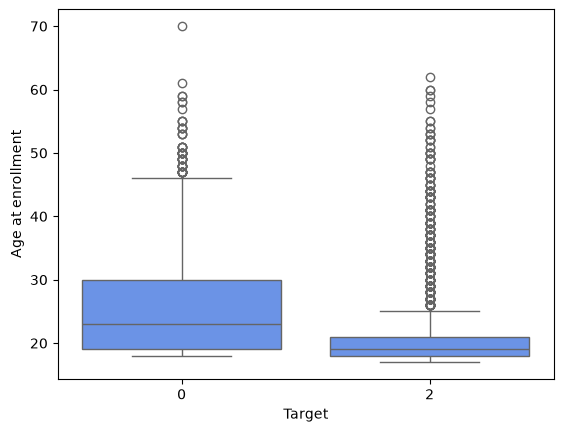

In [9]:
sns.boxplot(data=df, x='Target', y='Age at enrollment')

In [10]:
df['Age group'] = pd.cut(
    df['Age at enrollment'],
    bins=[0, 20, 25, 30, float('inf')],
    labels=['≤20', '21–25', '26–30', '31+']
)

df.groupby('Age group', observed=True)['Target'].apply(
    lambda x: (x == 0).mean() * 100
)

Age group
≤20      26.057692
21–25    45.665635
26–30    70.245399
31+      61.418685
Name: Target, dtype: float64

<Axes: xlabel='Age group', ylabel='Dropout rate (%)'>

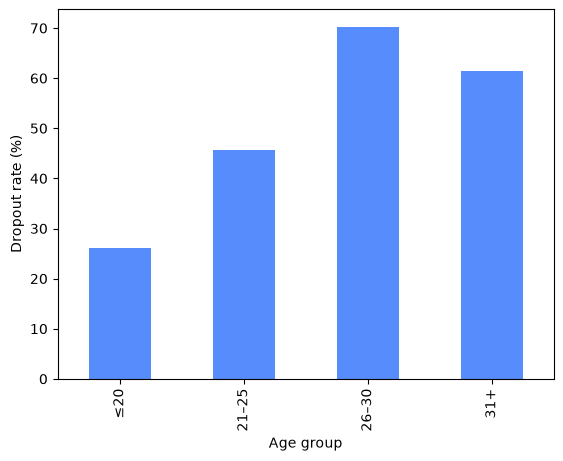

In [11]:
dropout_rate = df.groupby('Age group', observed=True)['Target'].apply(
    lambda x: (x == 0).mean() * 100
)

dropout_rate.plot(kind='bar', ylabel='Dropout rate (%)')

In [12]:
df['Age group'].value_counts().sort_index()

Age group
≤20      2080
21–25     646
26–30     326
31+       578
Name: count, dtype: int64

### 1. 1. 1. Comparison of enrolment characteristics

In [13]:
numeric = [
    'Age at enrollment',
    'Admission grade',
    'Previous qualification (grade)'
]

binary = [
    'Gender',
    'Debtor',
    'Scholarship holder',
    'Tuition fees up to date'
]

features = numeric + binary

summary = df.groupby('Target')[features].mean().T
summary.columns = ['Dropout', 'Graduate']

summary['Difference'] = summary['Dropout'] - summary['Graduate']
summary['Association'] = df[features].corrwith(
    (df['Target'] == 0).astype(int)
)

display(summary.round(3))

,Dropout,Graduate,Difference,Association
Age at enrollment,26.069,21.784,4.285,0.267
Admission grade,124.961,128.794,-3.833,-0.128
Previous qualification (grade),131.114,134.083,-2.969,-0.109
Gender,0.493,0.248,0.245,0.252
Debtor,0.220,0.046,0.174,0.267
Scholarship holder,0.094,0.378,-0.284,-0.313
Tuition fees up to date,0.678,0.987,-0.308,-0.442


### 1. 1. 2. Differences across degree programmes

In [14]:
cols = ['Age at enrollment', 'Admission grade', 'Debtor']

means = df.groupby(['Course', 'Target'])[cols].mean().unstack()
counts = df.groupby(['Course', 'Target']).size().unstack(fill_value=0)

result = pd.DataFrame({
    'N Dropout': counts[0],
    'N Graduate': counts[2],
    'Dropout %': counts[0] / counts.sum(axis=1) * 100,
    'Age difference': means['Age at enrollment'][0] - means['Age at enrollment'][2],
    'Grade difference': means['Admission grade'][0] - means['Admission grade'][2],
    'Debtor difference (pp)': (means['Debtor'][0] - means['Debtor'][2]) * 100
})

display(result[
    (result['N Dropout'] >= 20) &
    (result['N Graduate'] >= 20)
].round(2))

,N Dropout,N Graduate,Dropout %,Age difference,Grade difference,Debtor difference (pp)
Course,,,,,,
171,82,96,46.07,1.49,-9.40,14.30
8014,71,123,36.60,2.00,-4.75,12.40
9003,86,87,49.71,2.71,-10.25,23.39
9070,51,133,27.72,2.96,-6.08,16.31
9085,90,172,34.35,4.75,-4.12,24.97
9130,78,42,65.00,3.92,-6.10,25.64
9147,134,138,49.26,4.51,-5.71,9.15
9238,65,248,20.77,3.85,-3.43,18.82
9254,96,115,45.50,1.22,-3.43,21.01


In [15]:
table = pd.crosstab(df['Course'], df['Target'])

chi2, p, dof, expected = chi2_contingency(table)

v = (chi2 / (table.values.sum() * (min(table.shape) - 1))) ** 0.5

print(f"Chi-square: {chi2:.2f}")
print(f"p-value: {p:.4f}")
print(f"Cramér's V: {v:.3f}")

print("Minimum expected:", expected.min())
print("Expected < 5:", (expected < 5).sum())

Chi-square: 442.95
p-value: 0.0000
Cramér's V: 0.349
Minimum expected: 3.523140495867769
Expected < 5: 1


## 1. 1. 3. Findings and Limitations

### Main Findings

The analysis included 3,630 students with known outcomes: 1,421 dropouts and 2,209 graduates.

**Demographic characteristics:** Dropouts were older at enrollment than graduates (26.07 vs. 21.78 years, r = 0.267). The dropout rate increased from 26.06% among students aged 20 or younger to 70.25% among those aged 26–30. Gender also showed an association with dropout (r = 0.252).

**Educational characteristics:** Graduates had slightly higher admission grades (128.79 vs. 124.96) and previous qualification grades (134.08 vs. 131.11). Both showed relatively weak associations with dropout (r = -0.128 and -0.109).

**Financial characteristics:** These showed the strongest associations. Tuition fees up to date (r = -0.442) and scholarship holder status (r = -0.313) were negatively associated with dropout, while debtor status (r = 0.267) showed a positive association.

### Differences Across Degree Programmes

Dropout rates varied substantially across programmes, ranging from 17.72% (Course 9500) to 65.00% (Course 9130) among the 15 programmes included in the detailed comparison.

Dropouts were generally older and had lower admission grades than graduates, although the magnitude of these differences varied. Debtor status was more common among dropouts in all 15 programmes.

A chi-square test confirmed a statistically significant association between degree programme and academic outcome (χ²(16) = 442.95, p < 0.001). Cramér's V = 0.349 indicated a moderate association. Test assumptions were considered acceptable, with only one expected cell frequency below 5.

### Limitations

The analysis has several limitations:

- Excluding 794 students classified as Enrolled may introduce selection bias.
- Unknown categorical values may affect comparisons if not properly handled.
- The programme-level comparison excluded programmes with fewer than 20 students in either outcome group.
- Financial indicators may reflect circumstances during studies rather than conditions at enrollment.
- Observed associations do not establish causality.

### Conclusion

Financial characteristics showed the strongest associations with academic outcomes, followed by age and gender. Educational grades showed weaker associations. Differences across degree programmes were statistically significant, suggesting that programme-specific context is important when interpreting dropout patterns.

### 1. 2. Population question
Among students in the institution's undergraduate programmes
during the data-collection period, which enrolment-time characteristics are associated
with graduation or dropout?
- **Approach**: Estimate associations and subgroup differences with 95% confidence
intervals where justified.
- **Limitations**: Sampling procedures, cohort identifiers and collection dates are
insufficiently documented. Additional metadata is needed to assess
representativeness, selection bias and dependence between observations.

In [16]:
pop_df = df.copy()
pop_df["dropout"] = (pop_df["Target"] == 0).astype(int)

features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Gender"
]

rows = []

for feature in features:
    result = pearsonr(
        pop_df[feature],
        pop_df["dropout"]
    )

    ci = result.confidence_interval(0.95)

    rows.append({
        "Feature": feature,
        "r": result.statistic,
        "CI lower": ci.low,
        "CI upper": ci.high,
        "p-value": result.pvalue
    })

association_results = pd.DataFrame(rows)

display(association_results.round(4))

,Feature,r,CI lower,CI upper,p-value
0,Age at enrollment,0.2672,0.2368,0.2972,0.0
1,Admission grade,-0.1281,-0.1599,-0.0959,0.0
2,Previous qualification (grade),-0.1095,-0.1415,-0.0772,0.0
3,Gender,0.2520,0.2212,0.2822,0.0


In [17]:
course = pop_df.groupby("Course")["dropout"].agg(
    n="size",
    dropouts="sum"
)

course["dropout_share"] = (
    course["dropouts"] / course["n"]
)

course["ci_low"], course["ci_high"] = proportion_confint(
    course["dropouts"],
    course["n"],
    alpha=0.05,
    method="wilson"
)

display(course.round(3))

,n,dropouts,dropout_share,ci_low,ci_high
Course,,,,,
33,9,8,0.889,0.565,0.980
171,178,82,0.461,0.389,0.534
8014,194,71,0.366,0.301,0.436
9003,173,86,0.497,0.423,0.571
9070,184,51,0.277,0.218,0.346
9085,262,90,0.344,0.289,0.403
9119,106,92,0.868,0.790,0.920
9130,120,78,0.650,0.561,0.729
9147,272,134,0.493,0.434,0.552


In [18]:
selection_check = data.groupby("Target").agg(
    n=("Target", "size"),
    mean_age=("Age at enrollment", "mean"),
    mean_grade=("Admission grade", "mean")
)

selection_check.index = selection_check.index.map({
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate"
})

display(selection_check.round(2))

,n,mean_age,mean_grade
Target,,,
Dropout,1421,26.07,124.96
Enrolled,794,22.37,125.53
Graduate,2209,21.78,128.79


### 1.2.1. Conclusions and limitations

The analysis of 3,630 students with known outcomes identified associations between dropout and age at enrolment (r = 0.267), gender (r = 0.252), admission grade (r = −0.128), and previous qualification grade (r = −0.109). All four 95% confidence intervals excluded zero. Dropout proportions also varied across degree programmes, although estimates for smaller groups were less precise.

The exclusion of 794 Enrolled students (17.9%) may introduce selection bias. These students were younger than dropouts on average (22.37 vs. 26.07 years), while their admission grades were similar (125.53 vs. 124.96). Furthermore, incomplete information about sampling procedures, cohort structure and measurement timing limits population-level inference. Therefore, the findings describe associations among students with known outcomes but cannot be confidently generalized to the entire undergraduate population. The observed associations do not imply causality.